# Week 3 · Can we reliably shortlist breakout hitters?

A breakout is a gain of at least 20 unrounded wRC+ points in the next season, among
hitters with at least 300 PA in both seasons. Week 2 selected M2, traditional logistic
regression, on one validation season (2023 AP 0.4840). This analysis checks how the
nine candidates perform across three historical seasons. Run `python -m src.run_week3`
from the repository root to regenerate the results below.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Markdown, Image, display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from src.evaluate_models import markdown_table
from src.backtesting import VALIDATION_SEASONS

metrics = root / "results/metrics"
figures = root / "results/figures/week3"

def read_result(name):
    return pd.read_csv(metrics / f"week3_{name}.csv")

def show_table(frame):
    display(Markdown(markdown_table(frame)))

def show_figure(name):
    display(Image(filename=str(figures / f"{name}.png"), width=850))

## Chronological folds

A row becomes eligible for training when its following season ends. Each model fits
a fresh pipeline on the same training rows and scores the same validation hitters.
The shortened 2020 season yields two empty transitions under the 300-PA rule. The
2024 feature season is reserved for Week 4.

In [2]:
folds = read_result("backtesting_results")
design = folds.drop_duplicates("validation_season")
assert tuple(design.validation_season) == VALIDATION_SEASONS
assert design.training_outcome_max.le(design.validation_season).all()
show_table(design[["validation_season", "training_feature_seasons", "training_outcome_max",
                   "training_observations", "validation_observations", "validation_prevalence"]])

| validation_season | training_feature_seasons | training_outcome_max | training_observations | validation_observations | validation_prevalence |
| --- | --- | --- | --- | --- | --- |
| 2021 | 2017 2018 | 2019 | 406 | 192 | 0.1823 |
| 2022 | 2017 2018 2021 | 2022 | 598 | 202 | 0.1238 |
| 2023 | 2017 2018 2021 2022 | 2023 | 800 | 207 | 0.1739 |

## Nine-model comparison

M1–M5 repeat Week 2. M6–M7 use histogram gradient boosting, and M8–M9 use XGBoost,
with fixed settings and traditional or traditional-plus-Statcast predictors.
Mean AP gives seasons equal weight. Pooled AP ranks all out-of-fold predictions
together. Precision@20 counts the hits on each season's shortlist.

**M2** leads on mean AP. **M1** leads on mean Precision@20.

| experiment_id | model_name | feature_set | fold_count | mean_average_precision | std_average_precision | mean_roc_auc | mean_brier_score | mean_precision_at_20 | mean_recall_at_20 | pooled_average_precision |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| M2 | Logistic Regression | traditional | 3 | 0.3682 | 0.1022 | 0.7279 | 0.1261 | 0.4 | 0.2485 | 0.3243 |
| M3 | Logistic Regression | traditional_statcast | 3 | 0.3677 | 0.0916 | 0.7511 | 0.1282 | 0.4167 | 0.2545 | 0.3407 |
| M5 | Random Forest | traditional_statcast | 3 | 0.3651 | 0.1025 | 0.7213 | 0.1253 | 0.4 | 0.2523 | 0.3226 |
| M1 | Logistic Regression | baseline | 3 | 0.3627 | 0.0991 | 0.7005 | 0.1239 | 0.45 | 0.2806 | 0.3374 |
| M4 | Random Forest | traditional | 3 | 0.3459 | 0.0878 | 0.7137 | 0.1262 | 0.4 | 0.2483 | 0.3131 |
| M7 | HistGradientBoosting | traditional_statcast | 3 | 0.3449 | 0.0833 | 0.6973 | 0.1363 | 0.35 | 0.2164 | 0.3214 |
| M9 | XGBoost | traditional_statcast | 3 | 0.3235 | 0.0844 | 0.6987 | 0.1366 | 0.3833 | 0.2311 | 0.2938 |
| M6 | HistGradientBoosting | traditional | 3 | 0.3166 | 0.0892 | 0.6784 | 0.138 | 0.3167 | 0.2017 | 0.2804 |
| M8 | XGBoost | traditional | 3 | 0.3122 | 0.069 | 0.6868 | 0.1348 | 0.3667 | 0.2338 | 0.2789 |

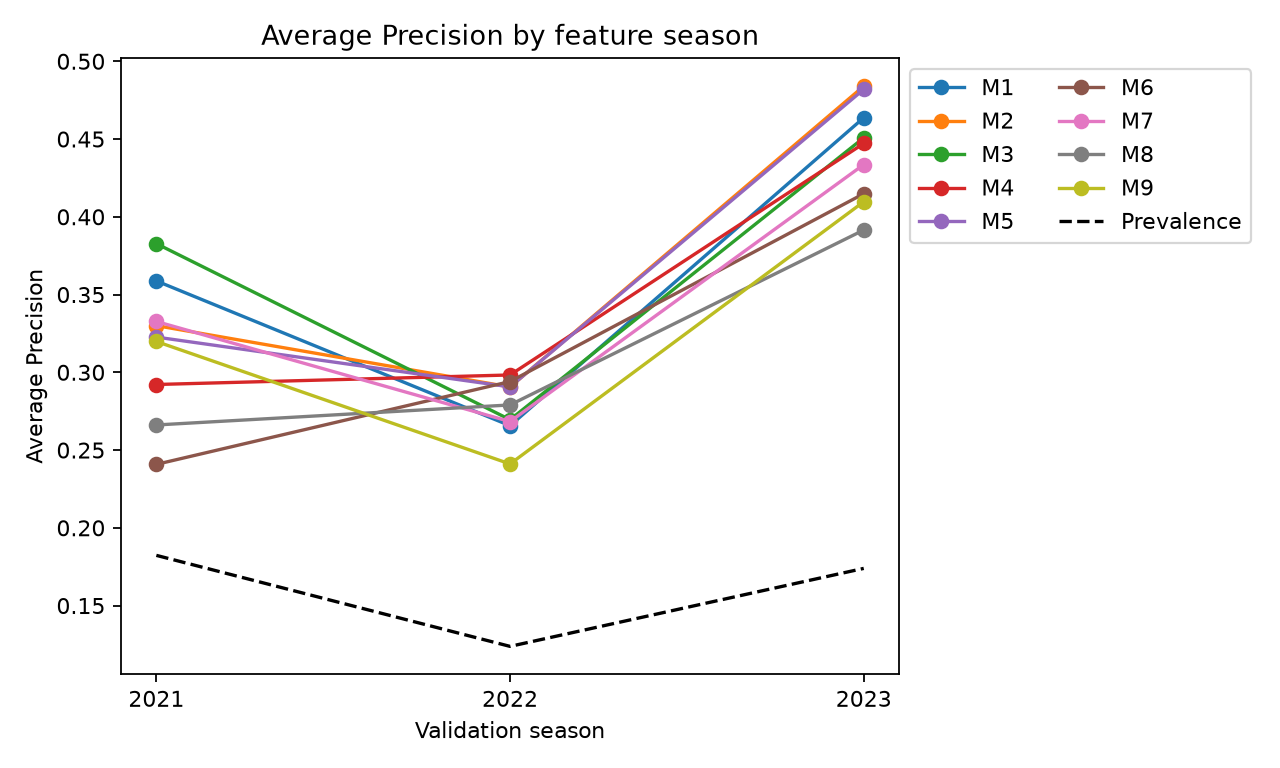

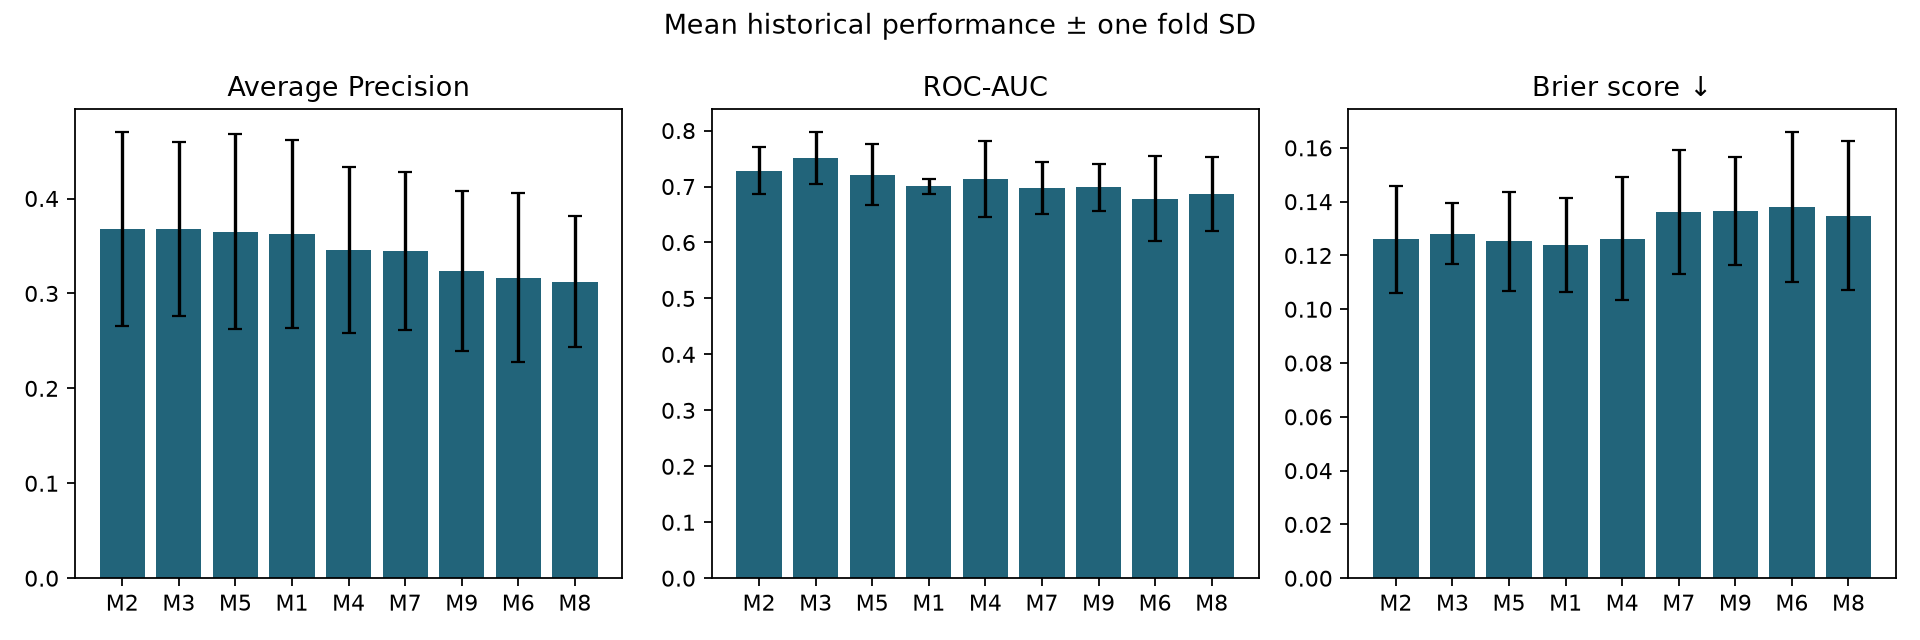

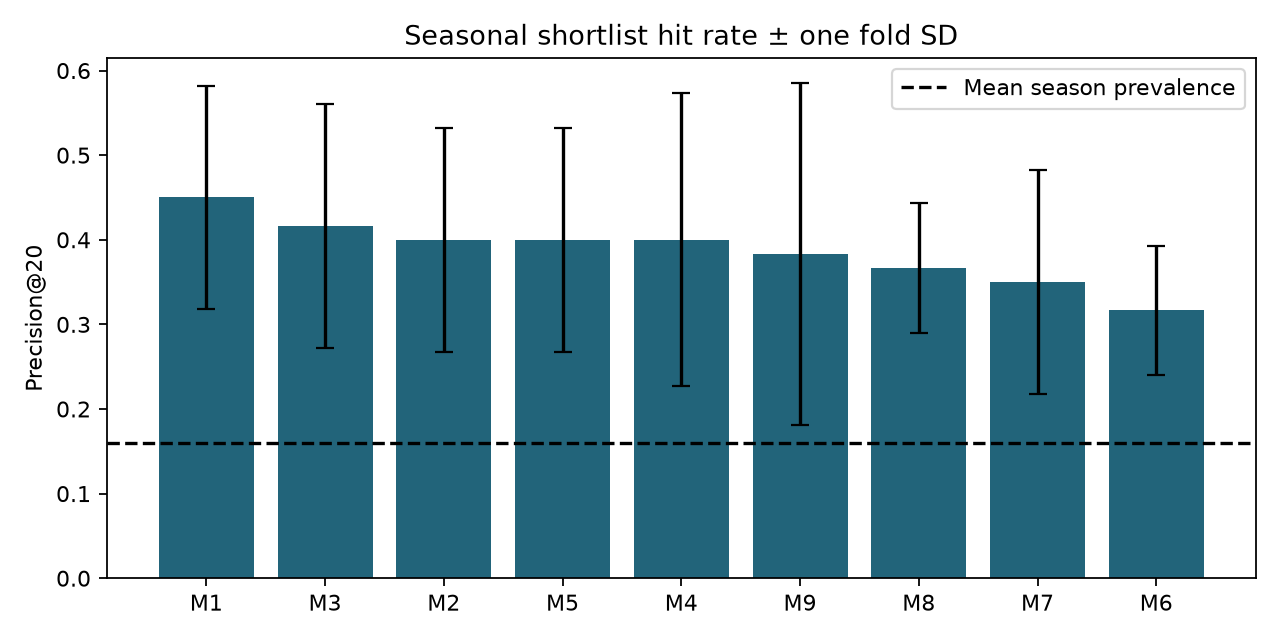

In [3]:
comparison = read_result("model_comparison")
shortlist = comparison.sort_values(["mean_precision_at_20", "experiment_id"],
                                   ascending=[False, True]).iloc[0]
display(Markdown(f"**{comparison.iloc[0].experiment_id}** leads on mean AP. "
                 f"**{shortlist.experiment_id}** leads on mean Precision@20."))
show_table(comparison)
show_figure("average_precision_by_fold")
show_figure("mean_performance")
show_figure("precision_at_20")

## Statcast and hitter age

Compare each traditional model with its Statcast counterpart within the same folds.
Age-group AP has a different prevalence reference in each band. The oldest band
had the smallest gains over its own prevalence for all three displayed models.

| model_name | delta_average_precision | delta_precision_at_20 |
| --- | --- | --- |
| HistGradientBoosting | 0.0283 | 0.0333 |
| Logistic Regression | -0.0005 | 0.0167 |
| Random Forest | 0.0192 | 0.0 |
| XGBoost | 0.0113 | 0.0167 |

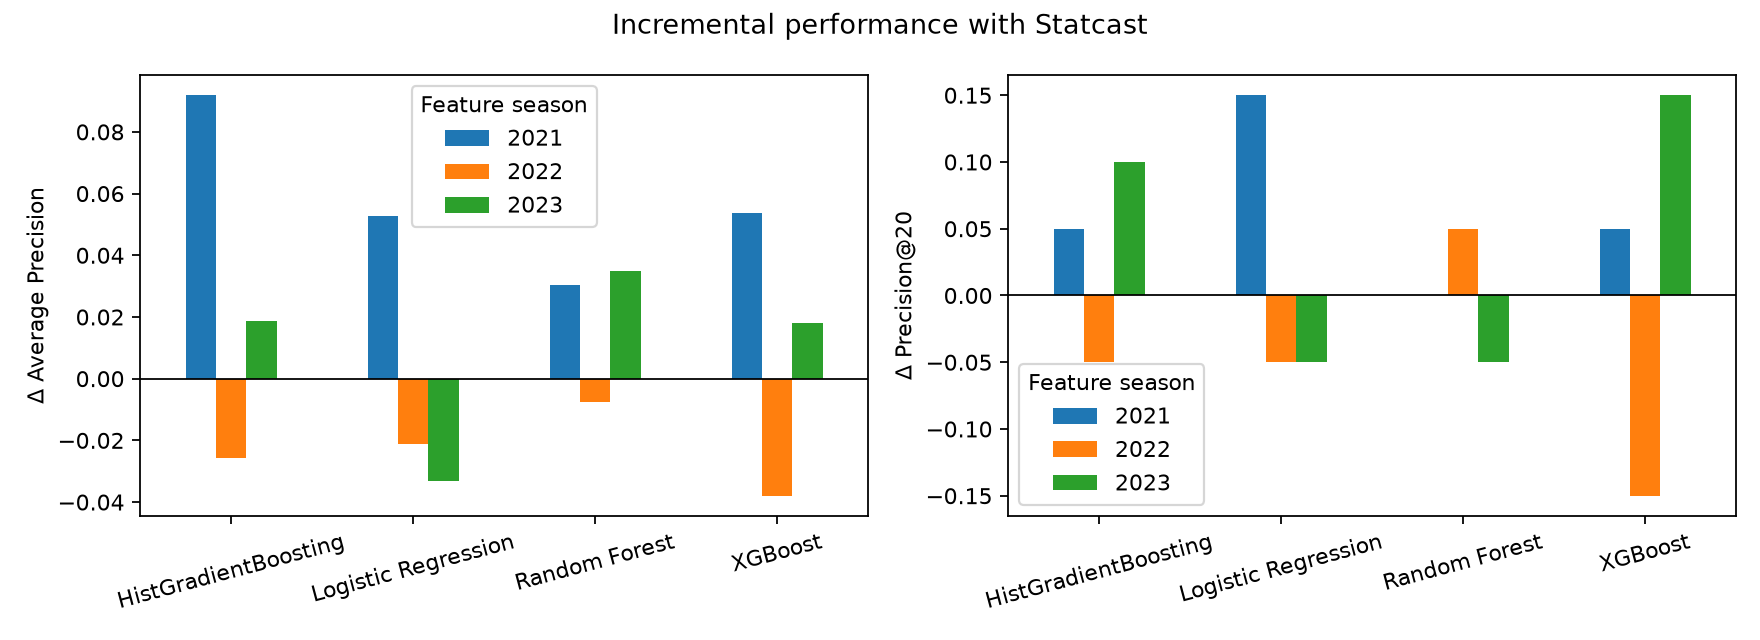

| experiment_id | age_group | observations | breakouts | prevalence | average_precision | roc_auc | brier_score | precision_at_10 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| M1 | ≤24 | 96 | 22 | 0.2292 | 0.4406 | 0.6714 | 0.1639 | 0.5 |
| M1 | 25–29 | 311 | 49 | 0.1576 | 0.3714 | 0.7095 | 0.12 | 0.5 |
| M1 | ≥30 | 194 | 25 | 0.1289 | 0.2422 | 0.6764 | 0.1095 | 0.2 |
| M2 | ≤24 | 96 | 22 | 0.2292 | 0.4116 | 0.656 | 0.1692 | 0.4 |
| M2 | 25–29 | 311 | 49 | 0.1576 | 0.3599 | 0.731 | 0.121 | 0.4 |
| M2 | ≥30 | 194 | 25 | 0.1289 | 0.2458 | 0.6798 | 0.1115 | 0.1 |
| M7 | ≤24 | 96 | 22 | 0.2292 | 0.4112 | 0.664 | 0.186 | 0.5 |
| M7 | 25–29 | 311 | 49 | 0.1576 | 0.3704 | 0.7537 | 0.1229 | 0.5 |
| M7 | ≥30 | 194 | 25 | 0.1289 | 0.1967 | 0.5572 | 0.1316 | 0.1 |

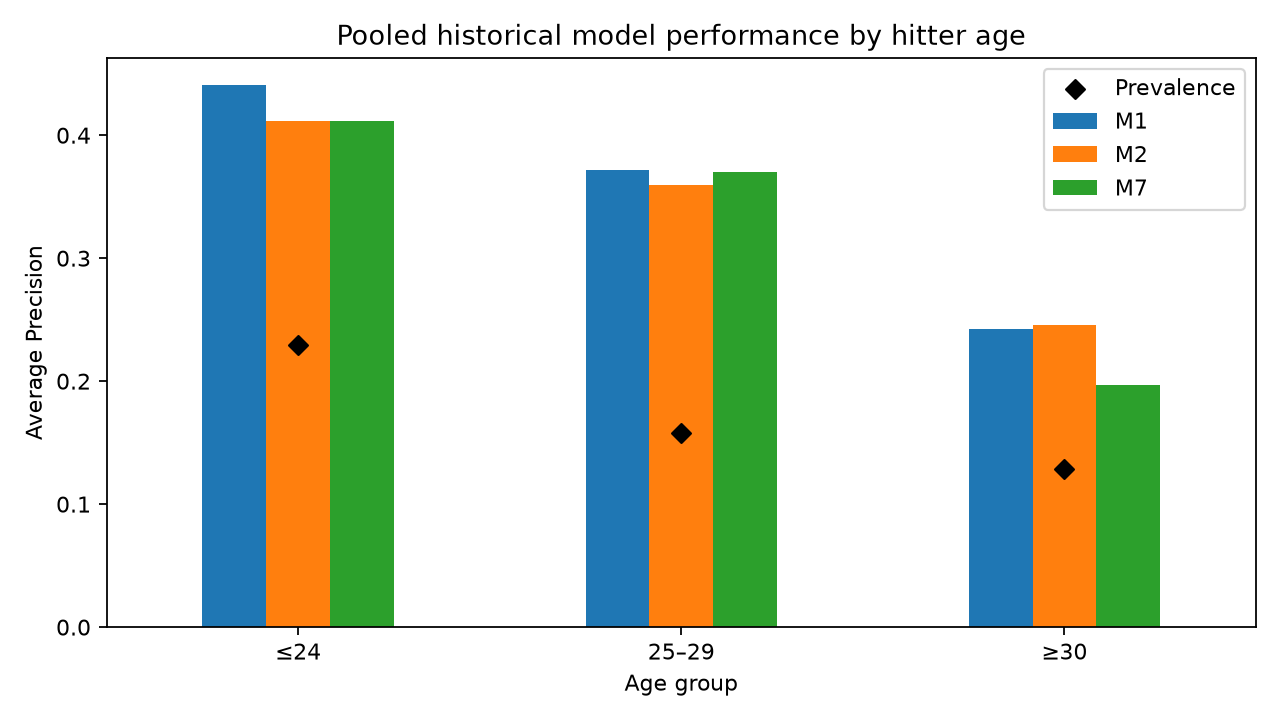

In [4]:
statcast = read_result("statcast_comparison")
show_table(statcast.groupby("model_name")[["delta_average_precision",
                                          "delta_precision_at_20"]].mean().reset_index())
show_figure("statcast_differences")
show_table(read_result("age_group_performance"))
show_figure("age_group_performance")

## Feature importance

M2 coefficients are standardized within training folds. Tree permutation importance
uses historical validation AP and repeated shuffles. Correlated inputs can share
signal, and starting wRC+ appears in the improvement target, so its importance can
partly reflect mathematical coupling and regression to the mean.

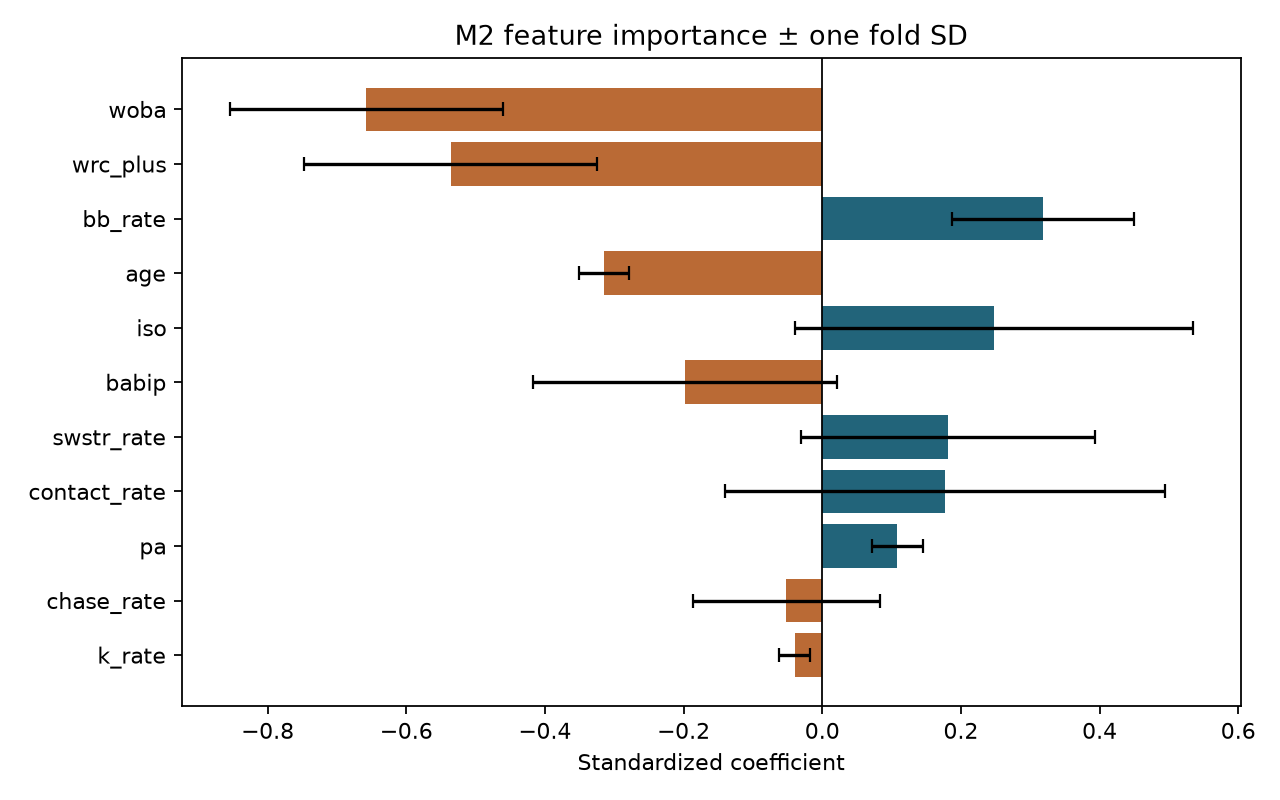

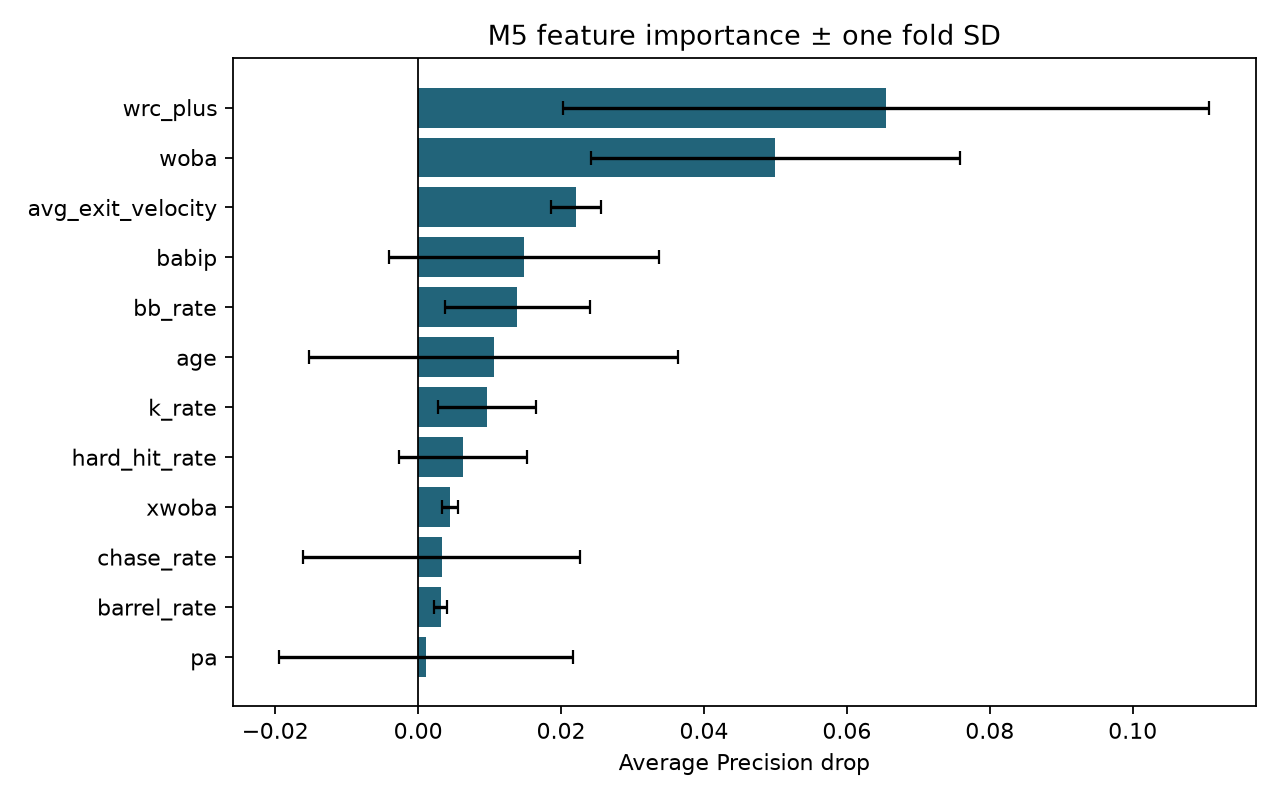

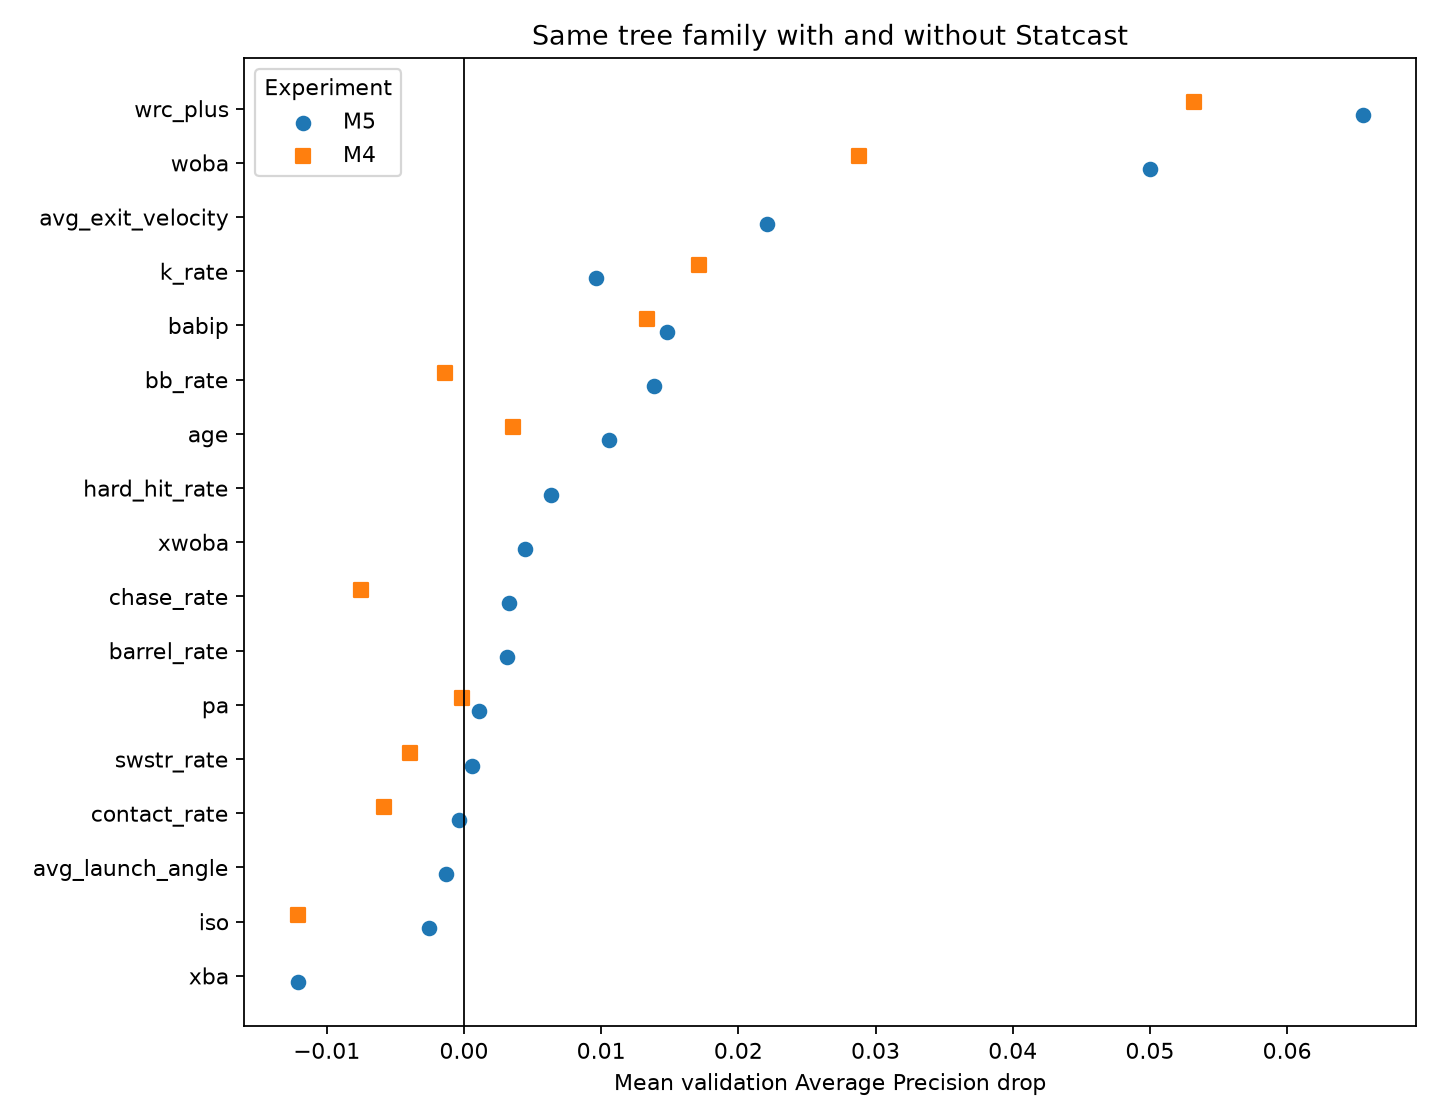

In [5]:
show_figure("logistic_coefficients")
show_figure("permutation_importance")
show_figure("statcast_importance")

## Hitter case studies

Classification cases use the 0.50 cutoff. Seasonal top-20 cases use rank and can
include hitters below that cutoff.

In [6]:
display(Markdown((metrics / "week3_case_studies.md").read_text(encoding="utf-8")))

# Historical hitter case studies

Cases use out-of-fold probabilities from M2 unless a different model is shown. Classification uses a 0.50 cutoff. Rates and expected stats describe the feature season.

## False Positive

M2 produced 13 cases in this category.

- **Jackie Bradley Jr. (2021, age 31, M2)** had a 86.3% score and moved from 36.3 to 56.0 wRC+ (+19.7). Starting xwOBA (0.252) sat 0.028 above observed wOBA, indicating a gap between expected and observed production.
- **Austin Hedges (2021, age 28, M2)** had a 84.1% score and moved from 42.0 to 42.7 wRC+ (+0.8). A 27.9% strikeout rate limited balls in play, alongside a 3.8% barrel rate on batted balls.
- **Taylor Walls (2022, age 25, M2)** had a 75.5% score and moved from 64.9 to 83.7 wRC+ (+18.8). Starting xwOBA (0.274) sat 0.022 above observed wOBA, indicating a gap between expected and observed production.

## False Negative

M2 produced 87 cases in this category.

- **Paul Goldschmidt (2021, age 33, M2)** had a 2.4% score and moved from 135.9 to 175.4 wRC+ (+39.5). Starting xwOBA (0.396) sat 0.023 above observed wOBA, indicating a gap between expected and observed production.
- **Aaron Judge (2021, age 29, M2)** had a 2.6% score and moved from 150.0 to 206.2 wRC+ (+56.2). Starting xwOBA (0.415) sat 0.028 above observed wOBA, indicating a gap between expected and observed production.
- **Aaron Judge (2023, age 31, M2)** had a 2.7% score and moved from 173.5 to 218.7 wRC+ (+45.2). Starting xwOBA (0.465) sat 0.045 above observed wOBA, indicating a gap between expected and observed production.

## True Positive

M2 produced 9 cases in this category.

- **Cody Bellinger (2021, age 25, M2)** had a 90.1% score and moved from 47.2 to 83.2 wRC+ (+36.0). Starting xwOBA (0.279) sat 0.042 above observed wOBA, indicating a gap between expected and observed production.
- **Geraldo Perdomo (2022, age 22, M2)** had a 77.7% score and moved from 58.5 to 98.2 wRC+ (+39.6). Starting xwOBA (0.274) sat 0.021 above observed wOBA, indicating a gap between expected and observed production.
- **Kevin Newman (2021, age 27, M2)** had a 69.4% score and moved from 51.6 to 91.5 wRC+ (+39.9). Starting xwOBA (0.278) sat 0.029 above observed wOBA, indicating a gap between expected and observed production.

## Per-season top 20

- **2021** yielded 7/20 hits. The highest-ranked non-breakout, Jackie Bradley Jr., ranked 2 with a +19.7 change. Aaron Judge gained +56.2 from rank 177.
- **2022** yielded 6/20 hits. The highest-ranked non-breakout, Taylor Walls, ranked 2 with a +18.8 change. Ronald Acuña Jr. gained +56.1 from rank 123.
- **2023** yielded 11/20 hits. The highest-ranked non-breakout, Nick Fortes, ranked 3 with a +6.3 change. Jurickson Profar gained +61.7 from rank 23.


## Calibration and thresholds

Sigmoid fits use inner chronological out-of-fold predictions. The reliability and
Brier comparisons use shared outer evaluation rows. The threshold grid is a
retrospective description of the precision–recall tradeoff.

| experiment_id | method | observations | prevalence | mean_probability | brier_score | intercept | slope |
| --- | --- | --- | --- | --- | --- | --- | --- |
| M1 | raw | 601 | 0.1597 | 0.1608 | 0.1236 | -0.2827 | 0.8153 |
| M1 | sigmoid | 601 | 0.1597 | 0.1547 | 0.1249 | 0.1002 | 1.0383 |
| M2 | raw | 601 | 0.1597 | 0.1754 | 0.1257 | -0.493 | 0.7297 |
| M2 | sigmoid | 601 | 0.1597 | 0.1496 | 0.1259 | -0.0911 | 0.8908 |
| M7 | raw | 601 | 0.1597 | 0.1626 | 0.1358 | -0.811 | 0.4152 |
| M7 | sigmoid | 601 | 0.1597 | 0.1482 | 0.1264 | 0.1115 | 1.011 |

| experiment_id | threshold | predicted_breakouts | precision | recall | f1 | fp | fn |
| --- | --- | --- | --- | --- | --- | --- | --- |
| M2 | 0.1 | 389 | 0.2082 | 0.8438 | 0.334 | 308 | 15 |
| M2 | 0.15 | 273 | 0.2527 | 0.7188 | 0.374 | 204 | 27 |
| M2 | 0.2 | 183 | 0.3115 | 0.5938 | 0.4086 | 126 | 39 |
| M2 | 0.25 | 135 | 0.3556 | 0.5 | 0.4156 | 87 | 48 |
| M2 | 0.3 | 95 | 0.3789 | 0.375 | 0.377 | 59 | 60 |
| M2 | 0.4 | 44 | 0.3864 | 0.1771 | 0.2429 | 27 | 79 |
| M2 | 0.5 | 22 | 0.4091 | 0.0938 | 0.1525 | 13 | 87 |

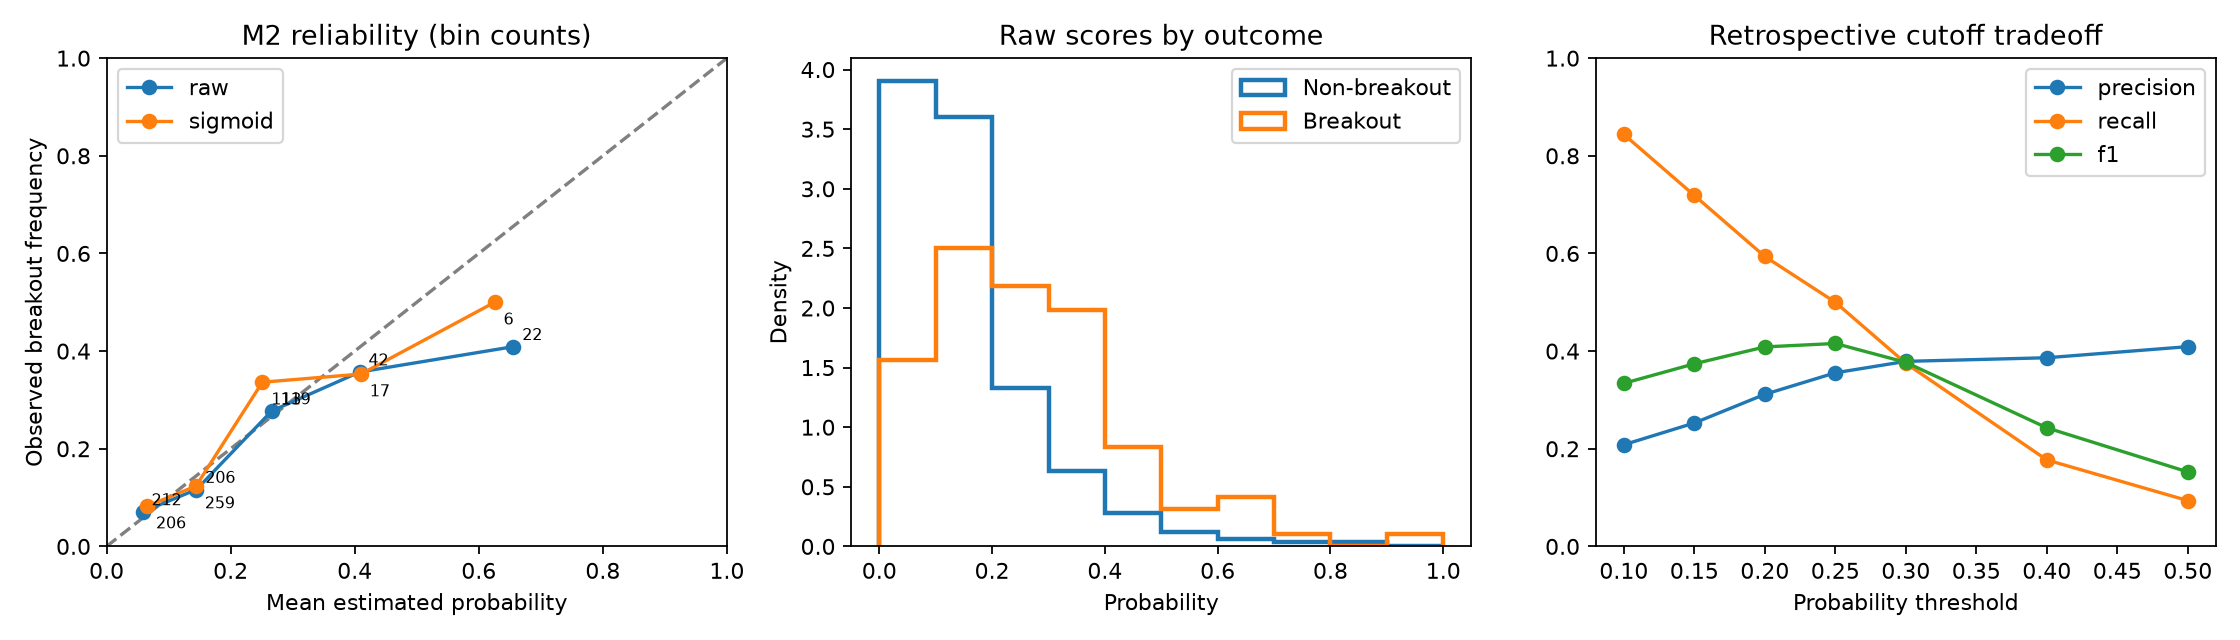

In [7]:
calibration = read_result("calibration_comparison")
show_table(calibration.loc[calibration.scope.eq("pooled_paired")].drop(
    columns=["scope", "calibration_observations"]))
show_table(read_result("threshold_analysis").query(
    "experiment_id == @comparison.iloc[0].experiment_id"))
show_figure("calibration_and_thresholds")

## Baseball operations and Week 4

The results support ranking a manageable number of candidates for scouting review.
A binary flag would require a defined review capacity or error cost and evidence
that probabilities transfer over time. Three seasons, sparse positives in some
bins, repeat players, and retrospective outcome-season playing-time qualification
limit generalization. Freeze the model and evaluation protocol before scoring the
2024→2025 holdout in Week 4.